# Stage 5: Model experiments
`scripts/03_run_experiments.py` fits and tunes on household-grouped training folds. Validation is used only for the reported comparison and the F1 threshold; no test rows are evaluated.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

root = Path.cwd() if (Path.cwd() / 'AGENTS.md').exists() else Path.cwd().parent
tables = root / 'reports' / 'tables'
print(pd.read_csv(tables / 'experiments.csv').to_string(index=False))


exp_id                  model imbalance_strategy                                                                                                                                                                                               best_params  cv_ap_mean  cv_ap_std  val_f1_at_0.5  val_f1_best  threshold  fit_seconds   val_ap  val_roc_auc  val_precision  val_recall   val_f1  val_prevalence  val_lift_at_10_percent  val_tn  val_fp  val_fn  val_tp
    E0                  dummy         stratified                                                                                                                                                                         {"model__strategy": "stratified"}    0.126031   0.000186       0.123506          NaN   0.500000     7.389065 0.126589     0.498823       0.124748    0.122288 0.123506        0.126845                0.965745    3055     435     445      62
    E1    logistic_regression         unweighted                                        

## Overfitting and underfitting
Compare training, grouped cross-validation and validation average precision. The learning curve subsamples whole household groups within each training fold.

                 model  train_ap    cv_ap  validation_ap  train_prevalence  val_prevalence  dummy_cv_ap  dummy_val_ap
   logistic_regression  0.289225 0.281063       0.281166          0.126923        0.126845     0.126031      0.126589
         random_forest  0.473151 0.307609       0.327734          0.126923        0.126845     0.126031      0.126589
hist_gradient_boosting  0.401356 0.297705       0.312313          0.126923        0.126845     0.126031      0.126589
                 model             ablation  cv_ap_mean  cv_ap_std  train_prevalence  val_prevalence  dummy_cv_ap  dummy_val_ap
         random_forest      individual_only    0.300946   0.018392          0.126923        0.126845     0.126031      0.126589
         random_forest individual_household    0.306083   0.013475          0.126923        0.126845     0.126031      0.126589
         random_forest         all_features    0.307609   0.016206          0.126923        0.126845     0.126031      0.126589
         random_

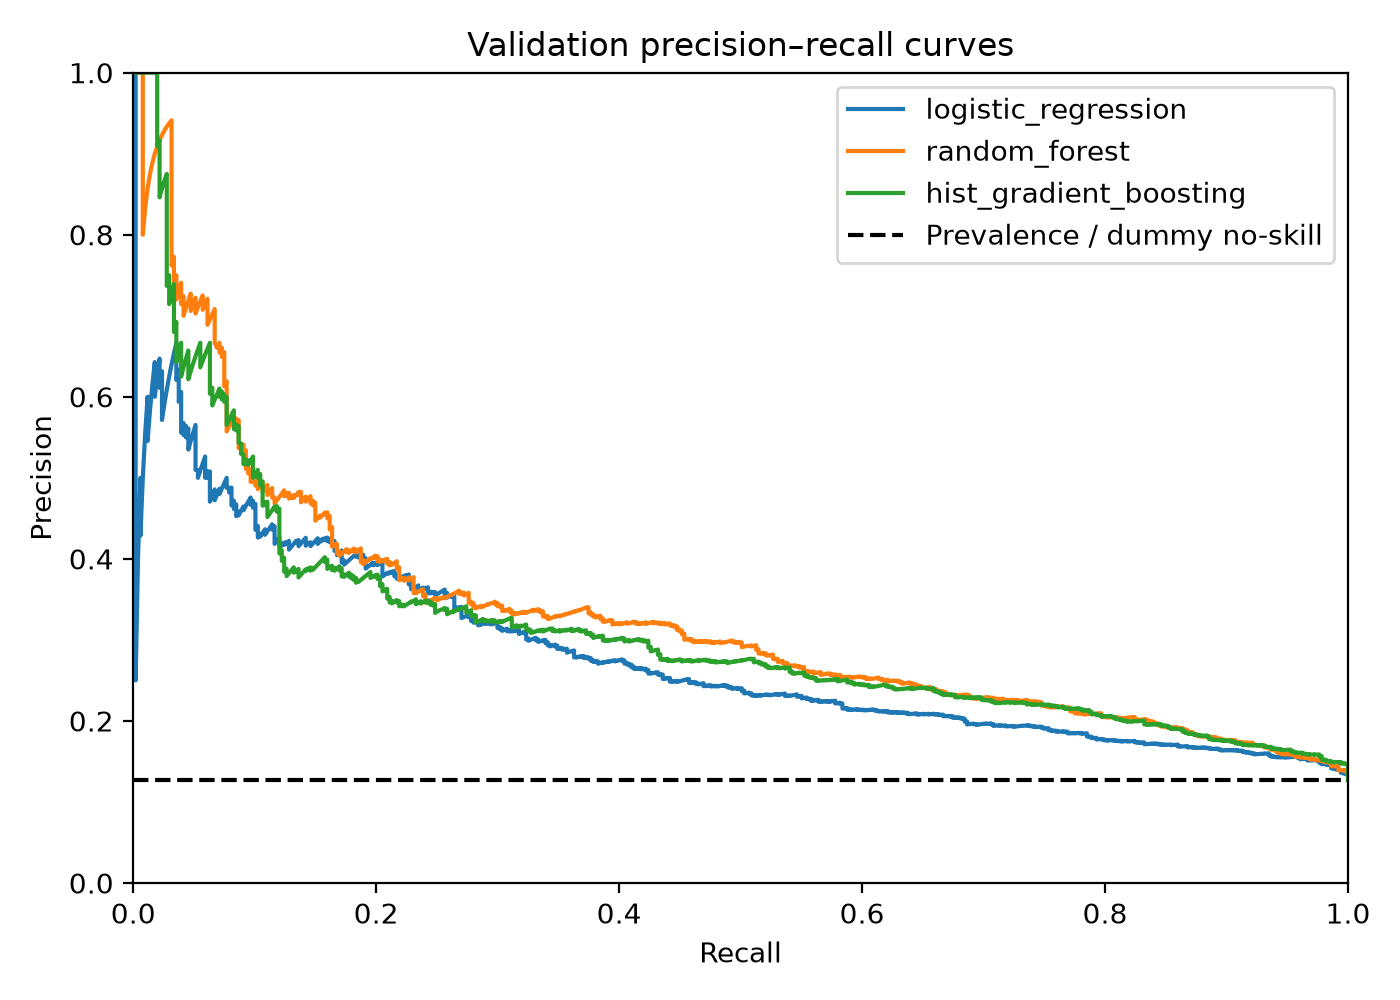

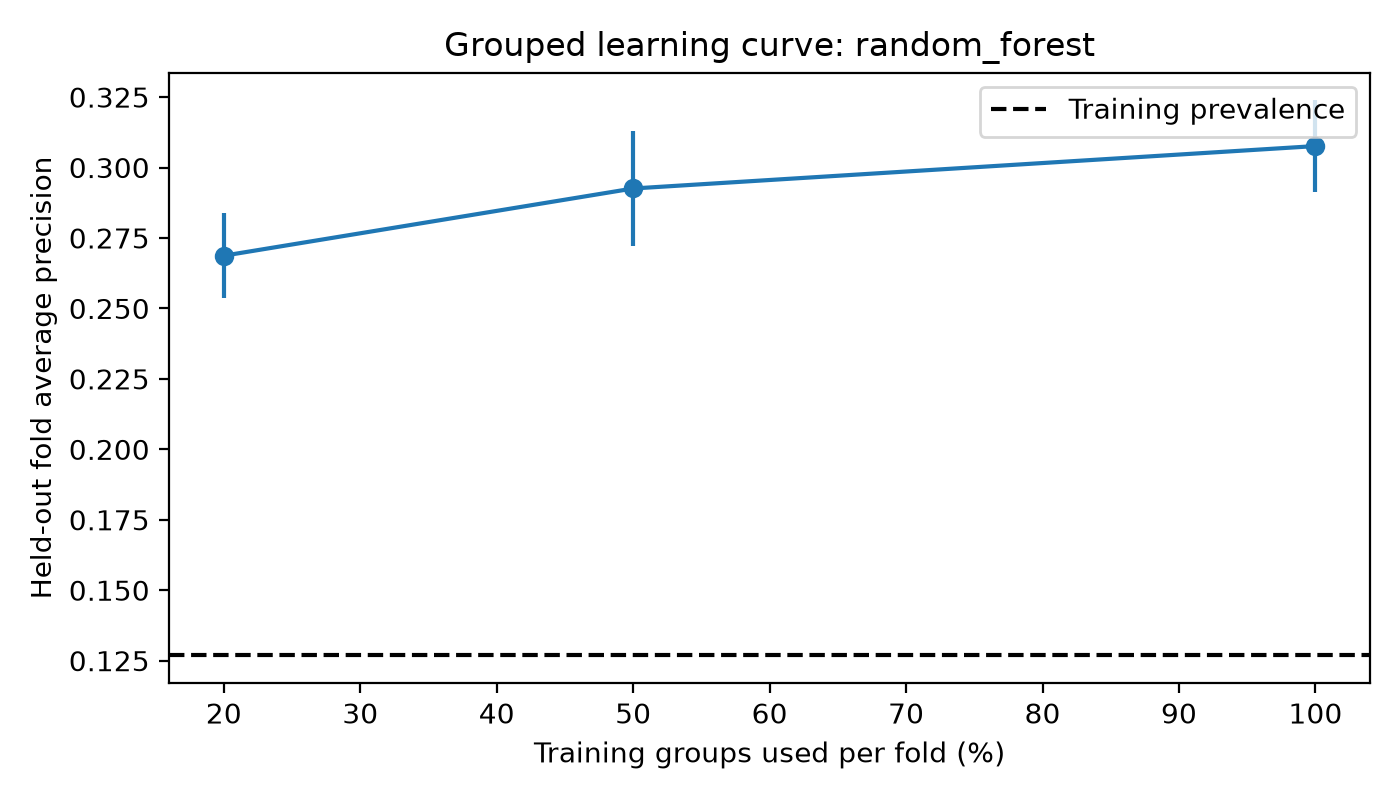

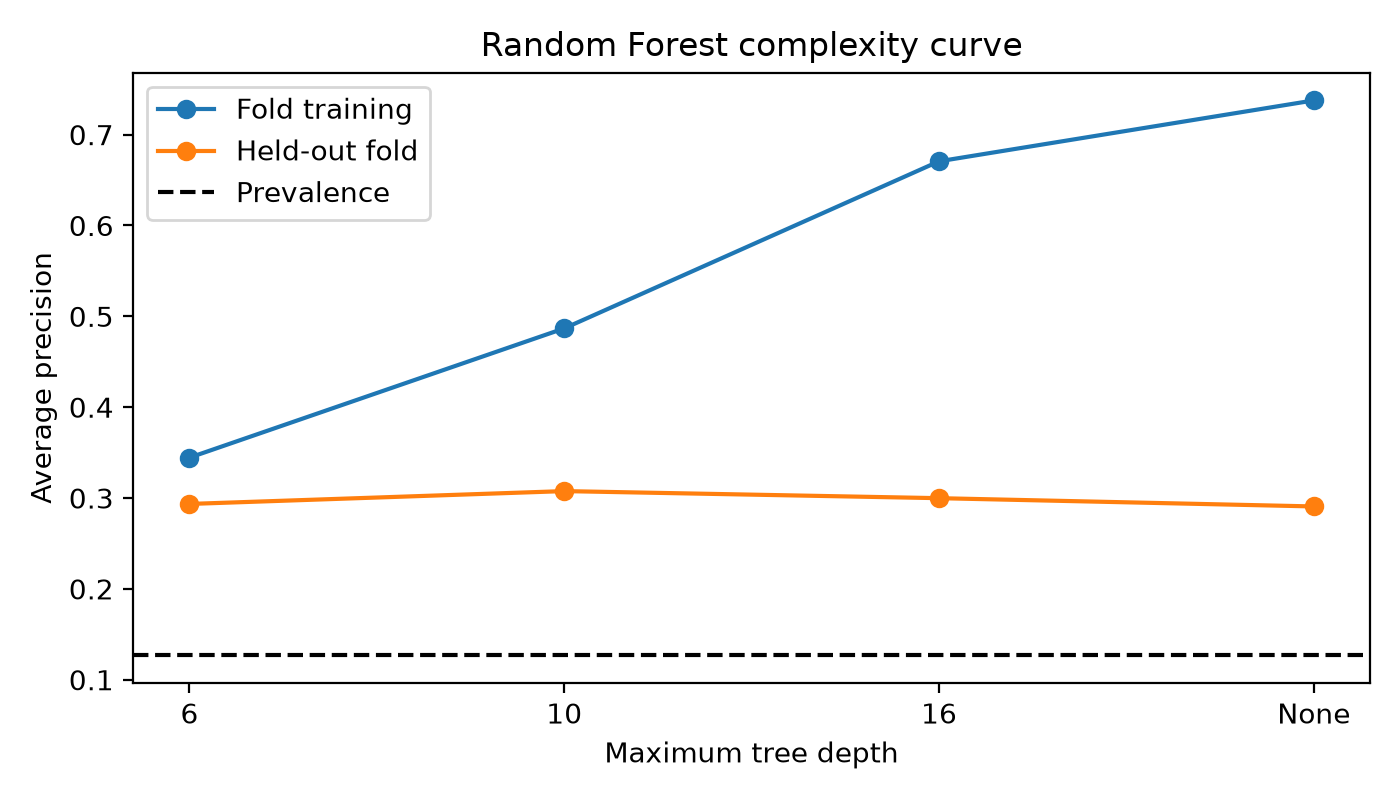

In [2]:
print(pd.read_csv(tables / 'generalization_gap.csv').to_string(index=False))
print(pd.read_csv(tables / 'feature_group_ablation.csv').to_string(index=False))
for name in ['validation_pr_curves', 'grouped_learning_curve', 'forest_validation_curve']:
    display(Image(filename=str(root / 'reports' / 'figures' / (name + '.png')), width=650))


## Gate G5
The team approved HistGradientBoosting in the 0.01 CV tie band, citing its smaller train-to-CV gap, smaller file and faster predictions. Random Forest had the highest held-out scores. Test data remains sealed.

## Gate G5: paired folds, HGB ablation and validation lift
The same five household-grouped training folds support paired differences. Standard deviations use the population convention used by the search results. Lift uses held-out validation rows only.

In [3]:
print('Grouped CV fold scores, paired differences, mean and standard deviation:')
print(pd.read_csv(tables / 'cv_fold_scores.csv').to_string(index=False))
print('HGB feature-group ablation:')
a = pd.read_csv(tables / 'feature_group_ablation.csv')
print(a.loc[a.model.eq('hist_gradient_boosting')].to_string(index=False))
print('Validation lift at 10% and 20%:')
print(pd.read_csv(tables / 'validation_lift.csv').to_string(index=False))

Grouped CV fold scores, paired differences, mean and standard deviation:
          fold  logistic_regression  random_forest  hist_gradient_boosting  rf_minus_hgb  hgb_minus_lr
             1             0.276685       0.289726                0.285259      0.004467      0.008574
             2             0.304811       0.333271                0.323661      0.009609      0.018850
             3             0.271991       0.297787                0.284008      0.013779      0.012018
             4             0.277195       0.297760                0.294840      0.002920      0.017645
             5             0.274635       0.319500                0.300757      0.018743      0.026121
          mean             0.281063       0.307609                0.297705      0.009904      0.016642
std_population             0.012014       0.016206                0.014379      0.005858      0.006037
HGB feature-group ablation:
                 model             ablation  cv_ap_mean  cv_ap_std  train_p